# CLIN: outlier candidates in `hist_obs`

`01_data_checks.ipynb` §6 flagged two kinds of suspicious values:
- **130 values with |z| > 6**, where z is the departure from the station's own seasonal cycle divided by the station's residual SD. That SD is one number per station for the whole year.
- **112 day-to-day jumps above 20 °C.**

This notebook collects all of them into one table, adds context, and plots them so you can judge what's going on. The context per candidate:
- **Neighbours:** how did stations within 300 km behave on the same day? A real cold outbreak shows up at neighbours too; a typo doesn't.
- **Spike shape:** is it a one-day excursion that jumps away and straight back?
- **Transcription hints:** would the value be normal if its sign were flipped, if it were °F, if it were Réaumur (common in 18th–19th century records: °C = 1.25 × °R), or if a decimal point slipped?

Transcription hints are only given when the corrected value brings the station within 3 °C of its neighbours' anomaly. A seasonally varying z (`z_seasonal`, using a per-month robust SD) is added as a second opinion. Winter days are naturally more variable, so the constant-SD z over-flags winter.

Output: `results/hist_obs_outlier_candidates.csv`

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings
import clin_common as cc
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN slices for sparse stations are expected

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#898781", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": .6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.titlesize": 9})

LAT, LON, ELEV, LSM = cc.load_static()
H, HD, HDOLY, meta, cell = cc.load_hist(LAT, LON)
obs = np.isfinite(H)
nday, nst = H.shape
print(H.shape, f"{obs.sum():,} observations")

(99710, 634) 6,876,041 observations


## 1. Each station's own seasonal cycle and residual spread

In [2]:
Hh = cc.harmonics(HDOLY)
clim = np.full_like(H, np.nan)
resid = np.full_like(H, np.nan)
for s in range(nst):
    m = obs[:, s]
    if m.sum() < 730: continue                     # need >= 2 years to fit a seasonal cycle
    coef = np.linalg.lstsq(Hh[m], H[m, s], rcond=None)[0]
    clim[:, s] = Hh @ coef
    resid[m, s] = H[m, s] - clim[m, s]

sd_const = np.nanstd(resid, 0)                     # the definition used in 01_data_checks
z = resid / sd_const

# Seasonal robust SD: per station and calendar month, 1.4826 * MAD
month = HD.month.values
sd_month = np.full((12, nst), np.nan)
for mo in range(1, 13):
    r = resid[month == mo]
    sd_month[mo - 1] = 1.4826 * np.nanmedian(np.abs(r - np.nanmedian(r, 0)), 0)
z_seas = resid / sd_month[month - 1]
print(f"stations with a fitted cycle: {np.isfinite(sd_const).sum()} / {nst}")
print(f"|z| > 6: {np.nansum(np.abs(z) > 6)} | |z_seasonal| > 6: {np.nansum(np.abs(z_seas) > 6)}")

stations with a fitted cycle: 608 / 634


|z| > 6: 130 | |z_seasonal| > 6: 57


## 2. Collect candidates (|z| > 6 or a jump > 20 °C into/out of the day)

In [3]:
jump_in = np.full_like(H, np.nan); jump_in[1:] = H[1:] - H[:-1]
jump_out = np.full_like(H, np.nan); jump_out[:-1] = H[1:] - H[:-1]
is_z = np.abs(z) > 6
is_jump = (np.abs(jump_in) > 20) | (np.abs(jump_out) > 20)
rows_, st_ = np.where(is_z | is_jump)
print(f"{len(rows_)} candidate station-days ({is_z.sum()} |z|>6, {(np.abs(jump_in) > 20).sum()} jumps > 20 C)")

# Neighbours within 300 km
lat_s, lon_s = meta.lat.values, meta.lon.values
def dist_km(i):
    la, lo = np.deg2rad(lat_s), np.deg2rad(lon_s)
    return 2 * 6371 * np.arcsin(np.sqrt(np.sin((la - la[i]) / 2)**2 + np.cos(la) * np.cos(la[i]) * np.sin((lo - lo[i]) / 2)**2))
NB_KM = 300
neigh = {s: np.where((dist_km(s) < NB_KM) & (np.arange(nst) != s))[0] for s in np.unique(st_)}

# Buddy check: station anomaly minus the median anomaly of its neighbours (in C), scaled by the
# robust SD of that difference for the same station and calendar month over the whole record.
buddy_diff, buddy_sd = {}, {}
for s in np.unique(st_):
    nbm = np.nanmedian(np.where(obs[:, neigh[s]], resid[:, neigh[s]], np.nan), 1) if len(neigh[s]) else np.full(nday, np.nan)
    n_av = obs[:, neigh[s]].sum(1) if len(neigh[s]) else np.zeros(nday, int)
    nbm[n_av < 2] = np.nan
    diff = resid[:, s] - nbm
    sdm = np.full(12, np.nan)
    for mo in range(1, 13):
        x = diff[(month == mo) & np.isfinite(diff)]
        if len(x) > 30: sdm[mo - 1] = 1.4826 * np.median(np.abs(x - np.median(x)))
    buddy_diff[s], buddy_sd[s] = (diff, nbm, n_av), sdm

def closer_to_neighbours(v_corr, cl, nbm, v):
    # a correction counts only if it brings the station within 3 C of its neighbours and halves the mismatch
    return abs(v_corr - cl - nbm) < min(3.0, 0.5 * abs(v - cl - nbm))

recs = []
for d, s in zip(rows_, st_):
    v, cl = H[d, s], clim[d, s]
    diff, nbm, n_av = buddy_diff[s]
    bz = diff[d] / buddy_sd[s][month[d] - 1]
    prev_, next_ = (H[d - 1, s] if d > 0 else np.nan), (H[d + 1, s] if d < nday - 1 else np.nan)
    spike = (np.isfinite(prev_) and np.isfinite(next_) and abs(v - prev_) > 10 and abs(v - next_) > 10
             and np.sign(v - prev_) == np.sign(v - next_))
    hints = []
    if np.isfinite(cl) and np.isfinite(nbm[d]):
        for name, vc in [("sign flip?", -v), ("degF?", (v - 32) * 5 / 9), ("Reaumur?", v * 1.25),
                         ("decimal?", v / 10), ("decimal?", v * 10)]:
            if closer_to_neighbours(vc, cl, nbm[d], v) and name not in hints: hints.append(name)
    if not np.isfinite(bz):
        verdict = "no neighbours"
    elif abs(bz) < 2.5:
        verdict = "neighbours agree"
    elif abs(bz) > 4:
        verdict = "isolated"
    else:
        verdict = "unclear"
    recs.append({"station_id": int(meta.id[s]), "station_col": s, "lon": lon_s[s], "lat": lat_s[s],
                 "date": HD[d].date(), "row": d, "value": v, "station_clim": cl, "z": z[d, s], "z_seasonal": z_seas[d, s],
                 "prev_day": prev_, "next_day": next_, "jump_in": jump_in[d, s], "jump_out": jump_out[d, s],
                 "flag_z6": bool(is_z[d, s]), "flag_jump20": bool(is_jump[d, s]), "one_day_spike": spike,
                 "n_neighbours": int(n_av[d]), "station_anom": v - cl, "neighbour_median_anom": nbm[d],
                 "buddy_z": bz, "verdict": verdict, "hints": ", ".join(hints)})
cand = pd.DataFrame(recs).sort_values(["station_id", "date"]).reset_index(drop=True)
cand.to_csv(cc.RESULTS_DIR / "hist_obs_outlier_candidates.csv", index=False)
print("saved results/hist_obs_outlier_candidates.csv")
display(cand.verdict.value_counts().to_frame("candidates"))
display(cand.hints.replace("", "-").value_counts().to_frame("candidates"))
print(f"one-day spikes: {cand.one_day_spike.sum()}")

347 candidate station-days (130 |z|>6, 112 jumps > 20 C)


saved results/hist_obs_outlier_candidates.csv


,candidates
verdict,
neighbours agree,157
isolated,92
unclear,65
no neighbours,33


,candidates
hints,
-,315
Reaumur?,14
decimal?,11
sign flip?,5
"sign flip?, decimal?",2


one-day spikes: 26


**Reading the verdicts:**
- **neighbours agree** (|buddy z| < 2.5): the station's anomaly matches the median anomaly of stations within 300 km, given how much the two usually differ in that month. This is probably a real extreme. Keep it.
- **isolated** (|buddy z| > 4): the station departs from its neighbours far more than usual. Suspect a data error, especially combined with *one-day spike* or a transcription hint.
- **unclear**: in between.
- **no neighbours** (common before ~1800): the value can't be cross-checked, so judge it from the time series.

stations with the most candidates:


,n,first,last,isolated
station_id,,,,
335,36,1865-02-12,1924-12-06,2
378,22,1911-01-05,1939-01-21,4
310,20,1903-01-03,1935-01-11,2
253,16,1865-02-12,1919-12-30,1
229,12,1804-12-30,1821-02-07,0
393,12,1902-12-04,1927-12-19,2
338,12,1882-12-17,1914-01-13,2
332,10,1895-01-30,1914-01-13,1
289,7,1913-01-29,1917-01-22,2


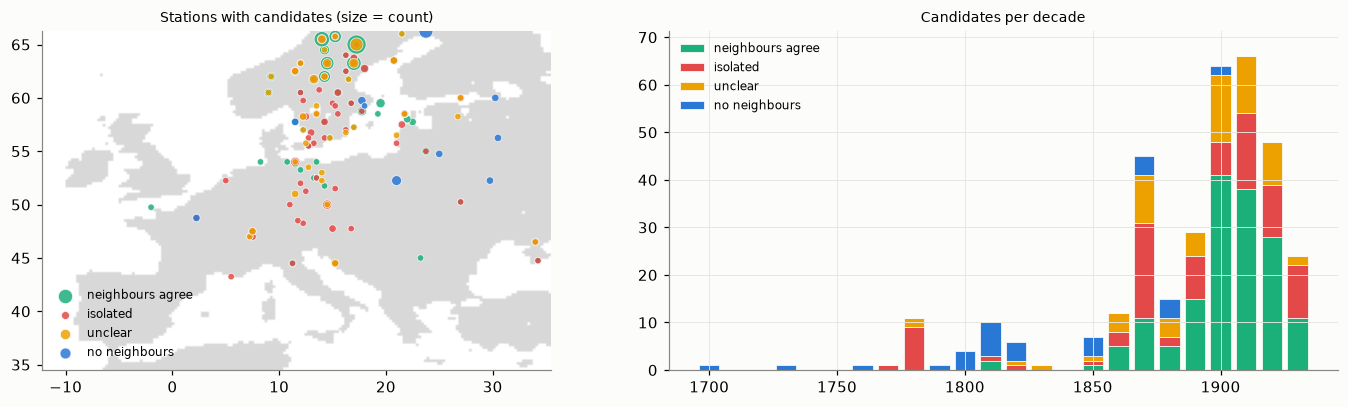

In [4]:
# Where and when are they concentrated?
per_station = cand.groupby("station_id").agg(n=("value", "size"), first=("date", "min"), last=("date", "max"),
                                             isolated=("verdict", lambda v: (v == "isolated").sum())).sort_values("n", ascending=False)
print("stations with the most candidates:"); display(per_station.head(10))
cand["decade"] = pd.to_datetime(cand.date).dt.year // 10 * 10

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].imshow(LSM > 0.5, extent=[LON[0], LON[-1], LAT[-1], LAT[0]], cmap="Greys", vmin=0, vmax=4); ax[0].grid(False)
for i, (v, col) in enumerate([("neighbours agree", C[2]), ("isolated", C[7]), ("unclear", C[3]), ("no neighbours", C[0])]):
    g = cand[cand.verdict == v].groupby("station_id").agg(lon=("lon", "first"), lat=("lat", "first"), n=("value", "size"))
    ax[0].scatter(g.lon, g.lat, s=12 + 6 * g.n, color=col, edgecolor="#fcfcfb", lw=.5, label=v, alpha=.85)
ax[0].legend(frameon=False, fontsize=8, loc="lower left"); ax[0].set_title("Stations with candidates (size = count)")
ct = cand.groupby(["decade", "verdict"]).size().unstack(fill_value=0)
bottom = np.zeros(len(ct))
for v, col in [("neighbours agree", C[2]), ("isolated", C[7]), ("unclear", C[3]), ("no neighbours", C[0])]:
    if v in ct:
        ax[1].bar(ct.index, ct[v], 8, bottom=bottom, color=col, label=v, edgecolor="#fcfcfb", lw=.5); bottom += ct[v].values
ax[1].set_title("Candidates per decade"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_ylim(0, bottom.max() * 1.08)
plt.tight_layout()

## 3. Look at them

Each panel shows ±15 days around the candidate (dashed line). The y-axis is the anomaly vs each station's own seasonal cycle:
- **Thick blue**: the flagged station.
- **Thin grey**: neighbours within 300 km.
- **Orange**: the neighbours' median.

Panel titles give the station, date, raw value, the station's normal value for that day, z, verdict and hints.

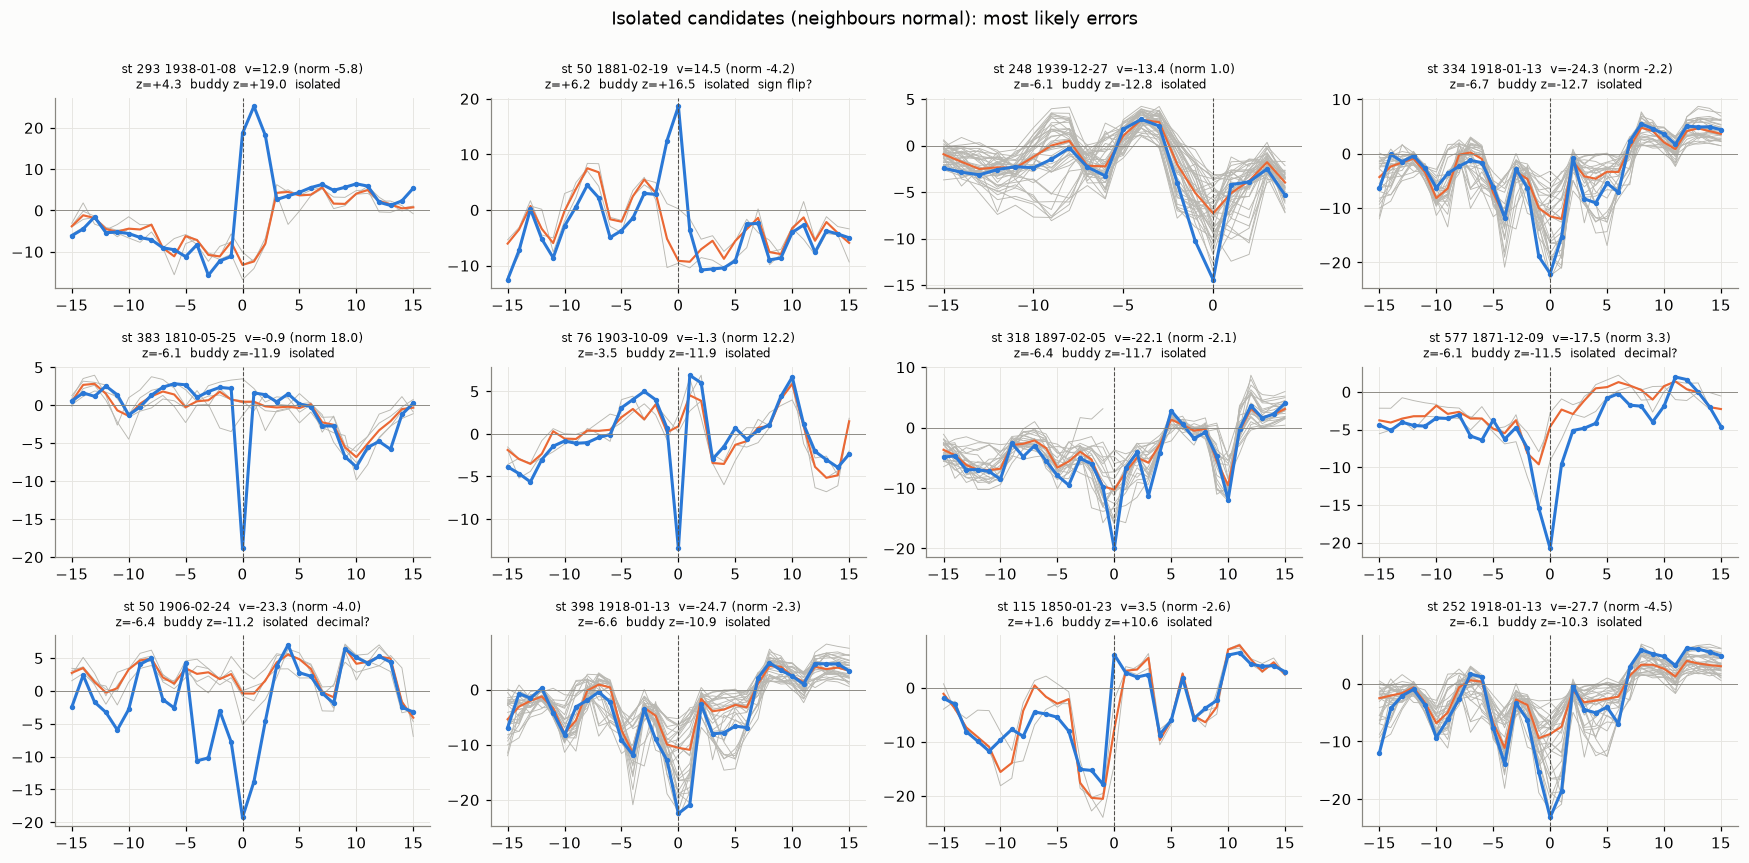

In [5]:
def plot_events(df, ncol=4, title=""):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow), squeeze=False)
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        d, s = int(r.row), int(r.station_col)
        w = np.arange(max(d - 15, 0), min(d + 16, nday)); x = w - d
        nb = neigh.get(s, np.array([], int))
        for j in nb:
            ax.plot(x, resid[w, j], color="#b9b8b2", lw=.6)
        if len(nb):
            ax.plot(x, buddy_diff[s][1][w], color=C[1], lw=1.4)
        ax.plot(x, resid[w, s], color=C[0], lw=2, marker="o", ms=2.5)
        ax.axvline(0, color="#52514e", ls="--", lw=.7); ax.axhline(0, color="#898781", lw=.6)
        ax.set_title(f"st {r.station_id} {r.date}  v={r.value:.1f} (norm {r.station_clim:.1f})\n"
                     f"z={r.z:+.1f}  buddy z={r.buddy_z:+.1f}  {r.verdict}  {r.hints}", fontsize=8)
    for ax in axs.ravel()[n:]: ax.axis("off")
    fig.suptitle(title, y=1.0); plt.tight_layout()

def worst(df, n):
    # rank by departure from neighbours where available, else by z
    key = df.buddy_z.abs().fillna(df.z.abs()).fillna(0)
    return df.loc[key.sort_values(ascending=False).index].head(n)

plot_events(worst(cand[cand.verdict == "isolated"], 12), title="Isolated candidates (neighbours normal): most likely errors")

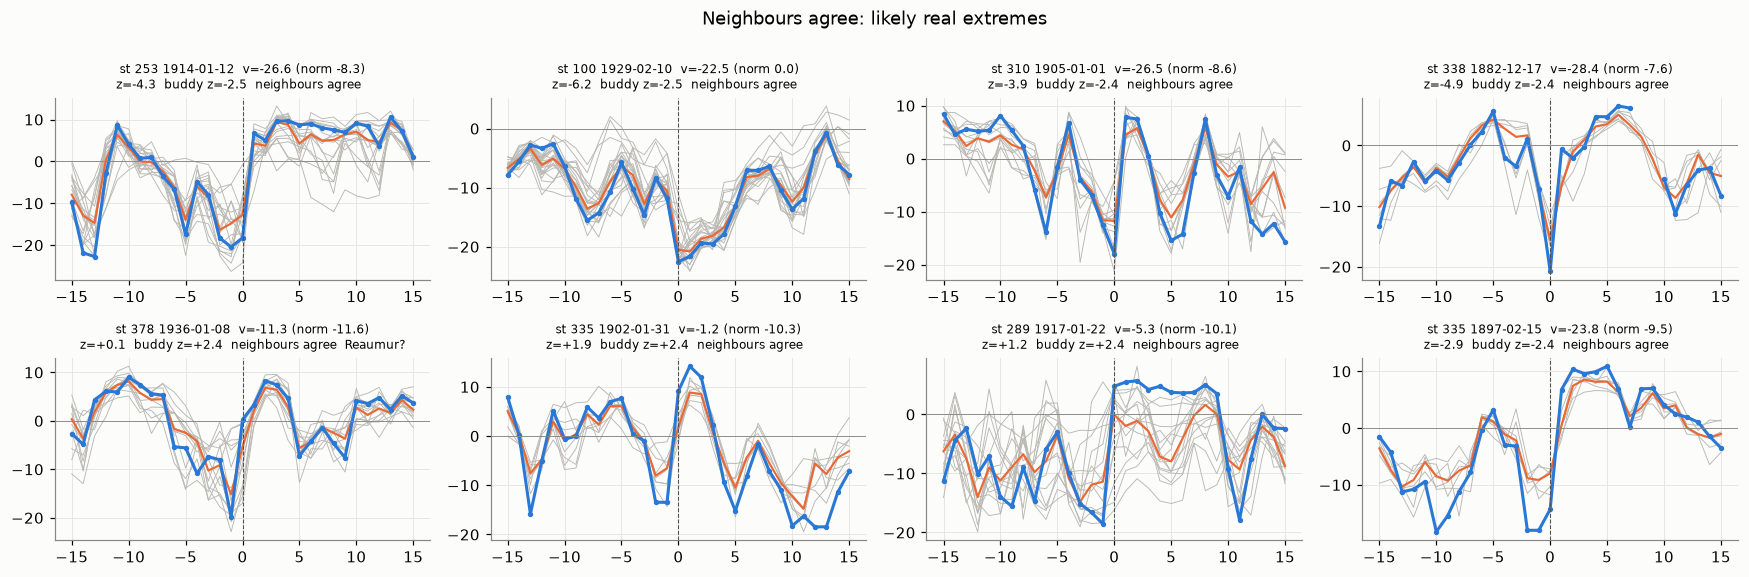

In [6]:
agree = cand[cand.verdict == "neighbours agree"]
plot_events(worst(agree, 8), title="Neighbours agree: likely real extremes")

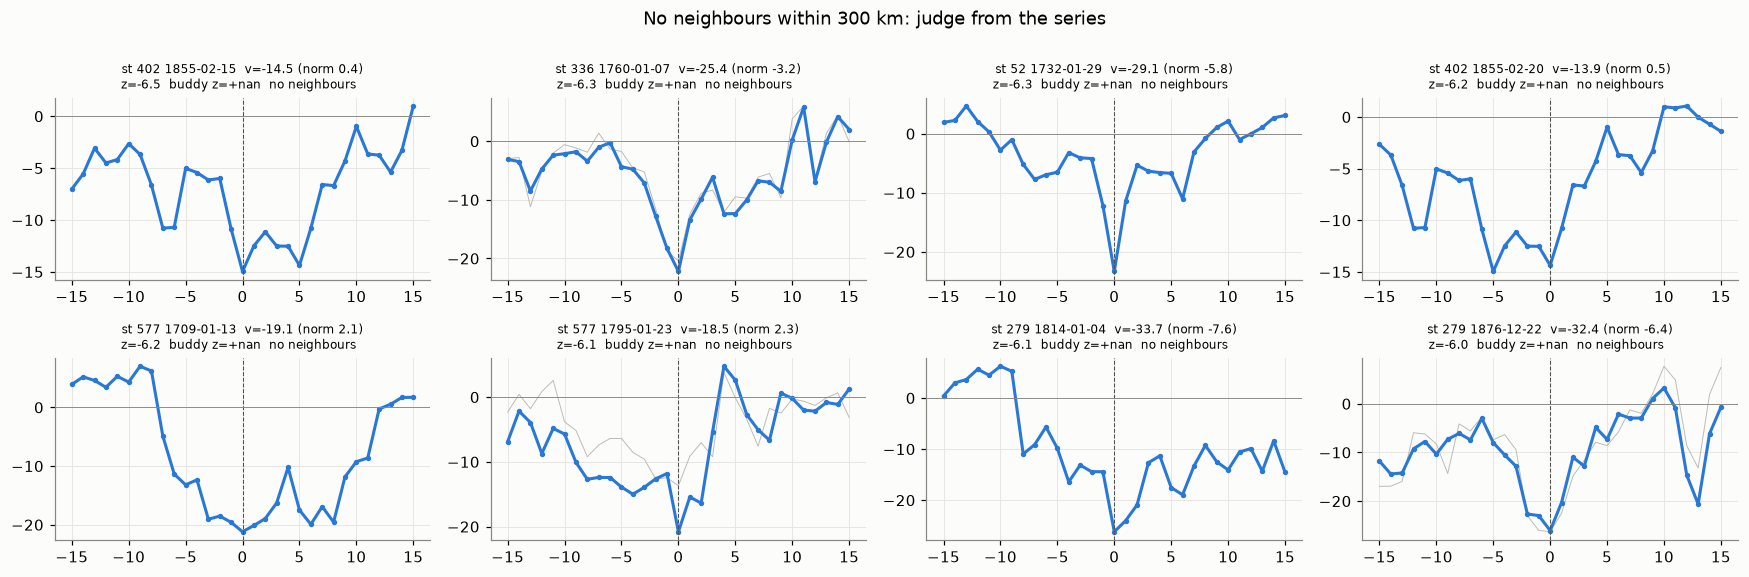

In [7]:
nonb = cand[cand.verdict == "no neighbours"]
plot_events(worst(nonb, 8), title="No neighbours within 300 km: judge from the series")

32 candidates with a transcription hint


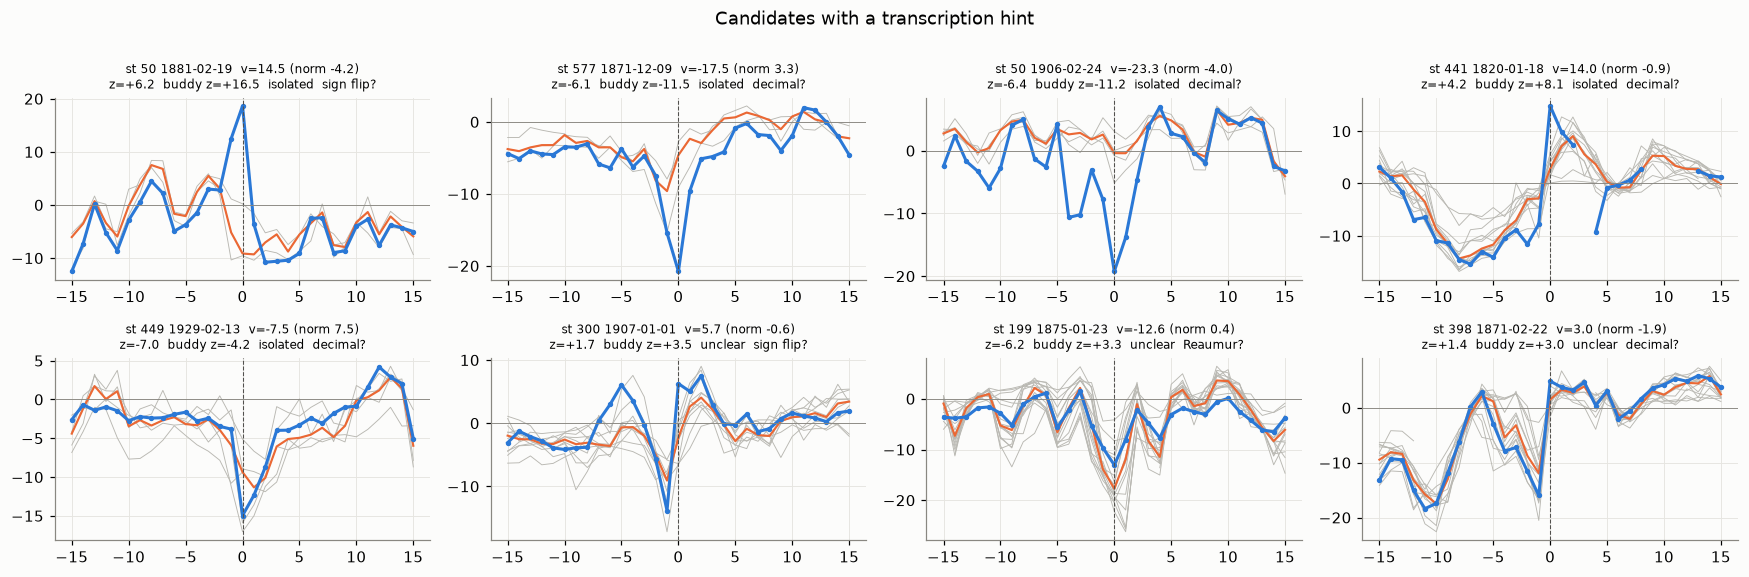

In [8]:
hinted = cand[cand.hints != ""]
print(f"{len(hinted)} candidates with a transcription hint")
if len(hinted):
    plot_events(worst(hinted, 8), title="Candidates with a transcription hint")

## 4. What to do with them

For the diffusion model (replacement inpainting) and for the regression baseline alike, every station value is treated as **exact**, so one bad value distorts the field around that cell. Options:

1. **Drop** candidates that are *isolated* + *one-day spike*, or that carry a transcription hint, before reconstruction. This is cheap and removes most real errors.
2. **Send** the CSV to the data provider for the *no neighbours* cases. Those can't be resolved statistically.
3. **Longer term:** treat observations as noisy (observation-error variance) rather than exact. The regression baseline supports this directly through its ridge term, and a conditional diffusion model can learn it.